<a href="https://colab.research.google.com/github/abhishiktadutta/RETAIL-ANALYTICS/blob/main/archive/legacy_synthetic_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install kagglehub

import pandas as pd, numpy as np, os, warnings
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 13
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.2 | numpy 2.0.2


In [ ]:
# ============================================================
#  SYNTHETIC RETAIL GENERATOR (vectorized)
#  Set the size here:
# ============================================================
N_ORDERS    = 50_000        # 5_200 ~ 10k rows | 50_000 ~ 100k | 250_000 ~ 520k
N_CUSTOMERS = 8_000         # rule of thumb: N_ORDERS / 6
OUT         = "retail_sales_synthetic.csv"

import numpy as np, pandas as pd
SEED = 42
rng  = np.random.default_rng(SEED)
START, END = pd.Timestamp("2021-01-01"), pd.Timestamp("2024-12-31")

# ---------- product catalogue -------------------------------
SUBCATS = [
    ("Furniture",       "Tables",      0.12,  120, 700, 14, 0.19, 0.08),
    ("Furniture",       "Bookcases",   0.17,   80, 420, 12, 0.16, 0.07),
    ("Furniture",       "Chairs",      0.23,   60, 380, 18, 0.11, 0.06),
    ("Furniture",       "Furnishings", 0.33,    8,  90, 22, 0.08, 0.05),
    ("Office Supplies", "Storage",     0.24,   20, 180, 20, 0.10, 0.05),
    ("Office Supplies", "Appliances",  0.28,   30, 320, 14, 0.11, 0.06),
    ("Office Supplies", "Supplies",    0.26,    5,  60, 16, 0.07, 0.04),
    ("Office Supplies", "Art",         0.40,    2,  30, 20, 0.05, 0.04),
    ("Office Supplies", "Binders",     0.44,    3,  45, 24, 0.20, 0.13),
    ("Office Supplies", "Envelopes",   0.42,    2,  22, 10, 0.06, 0.04),
    ("Office Supplies", "Fasteners",   0.38,    1,  12,  8, 0.06, 0.04),
    ("Office Supplies", "Labels",      0.47,    2,  18, 10, 0.05, 0.04),
    ("Office Supplies", "Paper",       0.45,    4,  40, 22, 0.05, 0.03),
    ("Technology",      "Machines",    0.20,  200,1800, 10, 0.17, 0.10),
    ("Technology",      "Copiers",     0.36,  180,1400,  8, 0.11, 0.07),
    ("Technology",      "Phones",      0.30,   60, 700, 20, 0.12, 0.07),
    ("Technology",      "Accessories", 0.34,    8, 160, 22, 0.09, 0.05),
]
BRANDS = ["Global","Eldon","Novimex","Hon","Ibico","Fellowes","Xerox","Acme",
 "Stockwell","Avery","Tenex","Sanford","Logitech","Belkin","Cardinal","Rogers",
 "Bush","Safco","Bevis","Wilson"]
ITEMS = {
 "Tables":["Conference Table","Training Table","Folding Table","Round Table"],
 "Bookcases":["Wood Bookcase","Metal Shelving","Corner Shelf","Library Unit"],
 "Chairs":["Task Chair","Executive Chair","Stacking Chair","Swivel Stool"],
 "Furnishings":["Desk Lamp","Wall Clock","Photo Frame","Door Stop"],
 "Storage":["File Box","Storage Drawer","Rolling Cart","Locker Unit"],
 "Appliances":["Air Purifier","Shredder","Coffee Maker","Space Heater"],
 "Supplies":["Scissors","Letter Opener","Staple Remover","Tape Gun"],
 "Art":["Pencil Set","Marker Pack","Highlighter","Sketch Pad"],
 "Binders":["Ring Binder","Clip Binder","Presentation Folder","Index Tabs"],
 "Envelopes":["Catalog Envelope","Window Envelope","Clasp Envelope","Mailer"],
 "Fasteners":["Paper Clips","Binder Clips","Push Pins","Rubber Bands"],
 "Labels":["Address Label","File Label","Shipping Label","Name Badge"],
 "Paper":["Copy Paper","Notebook","Memo Pad","Legal Pad"],
 "Machines":["Laser Printer","Fax Machine","Label Printer","Calculator"],
 "Copiers":["Digital Copier","Multifunction Copier","Desktop Copier","Color Copier"],
 "Phones":["Smart Phone","Cordless Phone","Conference Phone","Headset"],
 "Accessories":["Keyboard","Mouse","USB Hub","Memory Card"],
}

# catalogue grows with dataset size so products don't get absurdly over-ordered
CAT_MULT = max(1, int(np.ceil(N_ORDERS/5200) ** 0.5))
prods, pid = [], 0
for cat, sub, margin, clo, chi, k, dmean, dsd in SUBCATS:
    for _ in range(k * CAT_MULT):
        pid += 1
        cost = round(float(rng.uniform(clo, chi)), 2)
        prods.append((f"{cat[:3].upper()}-{sub[:2].upper()}-{10000+pid}",
            f"{rng.choice(BRANDS)} {rng.choice(ITEMS[sub])} {rng.integers(100,999)}",
            cat, sub, cost, round(cost/(1-margin),2), margin, dmean, dsd))
products = pd.DataFrame(prods, columns=["Product ID","Product Name","Category",
    "Sub-Category","unit_cost","list_price","gross_margin","d_mean","d_sd"])
NP = len(products)

# ---------- geography ---------------------------------------
GEO = {
 "West":[("California",["Los Angeles","San Francisco","San Diego","Fresno"]),
   ("Washington",["Seattle","Spokane"]),("Oregon",["Portland","Eugene"]),
   ("Arizona",["Phoenix","Tucson"]),("Colorado",["Denver","Aurora"])],
 "East":[("New York",["New York City","Rochester","Buffalo"]),
   ("Pennsylvania",["Philadelphia","Pittsburgh"]),
   ("Massachusetts",["Boston","Springfield"]),
   ("New Jersey",["Newark","Jersey City"]),("Ohio",["Columbus","Cleveland"])],
 "Central":[("Texas",["Houston","Dallas","Austin"]),("Illinois",["Chicago","Aurora"]),
   ("Michigan",["Detroit","Grand Rapids"]),("Minnesota",["Minneapolis","St. Paul"]),
   ("Missouri",["Kansas City","Springfield"])],
 "South":[("Florida",["Miami","Jacksonville","Tampa"]),("Georgia",["Atlanta","Savannah"]),
   ("North Carolina",["Charlotte","Raleigh"]),("Tennessee",["Nashville","Memphis"]),
   ("Virginia",["Richmond","Norfolk"])],
}
geo = pd.DataFrame([{"Region":r,"State":s,"City":c,
                     "Postal Code":int(rng.integers(10000,99999))}
                    for r,st in GEO.items() for s,cs in st for c in cs])
REGIONS, REGION_W = ["West","East","Central","South"], [0.32,0.29,0.22,0.17]
reg_pos = {r: np.flatnonzero((geo["Region"]==r).values) for r in REGIONS}

# ---------- customers (vectorized, unique names) -------------
FIRST = ["Aaron","Bella","Carlos","Diana","Ethan","Farah","Gavin","Hannah","Ian",
 "Jasmine","Kevin","Lena","Marcus","Nadia","Omar","Priya","Quentin","Rosa","Samir",
 "Tessa","Umar","Vera","Wesley","Xena","Yusuf","Zoe","Nina","Paul","Grace","Leo",
 "Maya","Noah","Olivia","Ravi","Sofia","Theo"]
LAST = ["Adams","Bennett","Chavez","Doyle","Ellis","Foster","Grant","Hughes","Iqbal",
 "Jensen","Khan","Lopez","Mehta","Novak","Owens","Patel","Quinn","Reyes","Silva",
 "Turner","Ueda","Vargas","Walsh","Xu","Young","Zhang","Brooks","Carter","Dixon","Fleming"]
MID = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

combos = np.array([f"{f} {m}. {l}" for f in FIRST for m in MID for l in LAST])
rng.shuffle(combos)                                    # 28,080 unique combinations
if N_CUSTOMERS <= len(combos):
    names = combos[:N_CUSTOMERS]
else:
    reps  = int(np.ceil(N_CUSTOMERS/len(combos)))
    names = np.concatenate([combos]*reps)[:N_CUSTOMERS]
    names = np.array([f"{nm} {i}" for i, nm in enumerate(names)])

c_reg = rng.choice(REGIONS, size=N_CUSTOMERS, p=REGION_W)
c_geo = np.empty(N_CUSTOMERS, dtype=int)
for r in REGIONS:
    m = c_reg == r
    c_geo[m] = rng.choice(reg_pos[r], size=m.sum())

customers = pd.DataFrame({
 "Customer ID":[f"{nm.split()[0][0]}{nm.split()[-1][0]}-{11000+i}"
                for i,nm in enumerate(names)],
 "Customer Name":names,
 "Segment":rng.choice(["Consumer","Corporate","Home Office"],
                      size=N_CUSTOMERS, p=[0.52,0.31,0.17]),
 "Region":geo["Region"].values[c_geo], "State":geo["State"].values[c_geo],
 "City":geo["City"].values[c_geo], "Postal Code":geo["Postal Code"].values[c_geo],
})
loyalty = rng.pareto(1.6, N_CUSTOMERS) + 1
cust_w  = loyalty / loyalty.sum()

# ---------- order-level draws (all vectorized) ---------------
SEASON = {1:.72,2:.78,3:.95,4:.92,5:.98,6:1.02,7:.94,8:1.0,9:1.15,10:1.10,11:1.34,12:1.42}
all_dates = pd.date_range(START, END, freq="D")
w = np.array([SEASON[d.month] for d in all_dates], float)
w *= 1.13 ** (np.arange(len(all_dates))/365.0)                  # ~13%/yr growth
w *= np.where(all_dates.dayofweek.isin([5,6]), 0.55, 1.0)       # weekend dip
w /= w.sum()

SHIP_MODES = np.array(["Standard Class","Second Class","First Class","Same Day"])
SHIP_W   = [0.60,0.19,0.15,0.06]
SD_LO, SD_HI = np.array([4,3,1,0]), np.array([7,5,3,1])
SHIP_FEE = np.array([2.5,4.5,8.0,15.0])
SEG_BUMP = {"Consumer":0.0,"Corporate":0.012,"Home Office":0.025}

dpos    = rng.choice(len(all_dates), size=N_ORDERS, p=w)
o_date  = all_dates.values[dpos]
o_month = all_dates.month.values[dpos]
o_year  = all_dates.year.values[dpos]
o_cust  = rng.choice(N_CUSTOMERS, size=N_ORDERS, p=cust_w)
o_mode  = rng.choice(4, size=N_ORDERS, p=SHIP_W)
o_sdays = rng.integers(SD_LO[o_mode], SD_HI[o_mode]+1)
o_id    = ("US-" + pd.Series(o_year).astype(str) + "-" +
           pd.Series(100000+np.arange(1,N_ORDERS+1)).astype(str)).values

# ---------- expand to line level ----------------------------
n_lines = rng.choice([1,2,3,4,5], size=N_ORDERS, p=[.42,.28,.16,.09,.05])
L  = int(n_lines.sum())
oi = np.repeat(np.arange(N_ORDERS), n_lines)

p_idx = rng.integers(0, NP, size=L)
qty   = rng.choice(np.arange(1,9), size=L, p=[.30,.24,.17,.11,.08,.05,.03,.02])

seg_line = customers["Segment"].values[o_cust][oi]
bump = np.vectorize(SEG_BUMP.get)(seg_line).astype(float)
d = rng.normal(products["d_mean"].values[p_idx],
               products["d_sd"].values[p_idx]) + bump
clear = np.isin(o_month[oi],[1,7]) & (rng.random(L) < 0.11)     # Jan/Jul clearance
d[clear] += rng.uniform(0.08, 0.22, clear.sum())
bulk = (rng.random(L) < 0.04) & (qty >= 5)
d[bulk] += 0.10
d = np.clip(np.round(d/0.05)*0.05, 0.0, 0.80)

lp, uc = products["list_price"].values[p_idx], products["unit_cost"].values[p_idx]
sales  = qty * lp * (1-d)
cogs   = qty * uc
ship   = SHIP_FEE[o_mode][oi] * (1 + 0.04*qty)
profit = sales - cogs - ship

gi = c_geo[o_cust][oi]
df = pd.DataFrame({
 "Order ID":o_id[oi], "Order Date":o_date[oi],
 "Ship Date":o_date[oi] + o_sdays[oi].astype("timedelta64[D]"),
 "Ship Mode":SHIP_MODES[o_mode][oi],
 "Customer ID":customers["Customer ID"].values[o_cust][oi],
 "Customer Name":customers["Customer Name"].values[o_cust][oi],
 "Segment":seg_line, "Country":"United States",
 "City":geo["City"].values[gi], "State":geo["State"].values[gi],
 "Postal Code":geo["Postal Code"].values[gi], "Region":geo["Region"].values[gi],
 "Product ID":products["Product ID"].values[p_idx],
 "Category":products["Category"].values[p_idx],
 "Sub-Category":products["Sub-Category"].values[p_idx],
 "Product Name":products["Product Name"].values[p_idx],
 "Sales":sales.round(2), "Quantity":qty, "Discount":d.round(2),
 "Profit":profit.round(2),
})
df = df.drop_duplicates(subset=["Order ID","Product ID"]).reset_index(drop=True)

# ---------- inject data-quality issues ----------------------
n = len(df)
i1 = rng.choice(n, int(n*0.004), replace=False)                # bulk outliers
df.loc[i1,"Quantity"] = rng.integers(30,90,len(i1))
df.loc[i1,"Sales"]  = (df.loc[i1,"Sales"] *rng.uniform(9,14,len(i1))).round(2)
df.loc[i1,"Profit"] = (df.loc[i1,"Profit"]*rng.uniform(8,13,len(i1))).round(2)

df["Order Date"] = pd.to_datetime(df["Order Date"]).dt.strftime("%d-%m-%Y")
df["Ship Date"]  = pd.to_datetime(df["Ship Date"]).dt.strftime("%d-%m-%Y")
bad = rng.choice(n, int(n*0.009), replace=False)
df.loc[bad,"Ship Date"] = rng.choice(["","N/A","unknown","00-00-0000"], len(bad))

neg = rng.choice(n, int(n*0.003), replace=False)               # negative delays
tmp = pd.to_datetime(df.loc[neg,"Order Date"], dayfirst=True, errors="coerce")
df.loc[neg,"Ship Date"] = (tmp - pd.to_timedelta(
    rng.integers(1,4,len(neg)), unit="D")).dt.strftime("%d-%m-%Y")

lo = rng.choice(n, int(n*0.05), replace=False)                 # casing
df.loc[lo,"Ship Mode"] = df.loc[lo,"Ship Mode"].str.lower()
up = rng.choice(n, int(n*0.02), replace=False)
df.loc[up,"Ship Mode"] = df.loc[up,"Ship Mode"].str.upper()

ty = rng.choice(n, int(n*0.012), replace=False)                # region typos
df.loc[ty,"Region"] = df.loc[ty,"Region"].map(
    {"West":"Wets","East":"Est","Central":"Centrl","South":"Sout"})

ws = rng.choice(n, int(n*0.04), replace=False)                 # whitespace
df.loc[ws,"Customer Name"] = "  " + df.loc[ws,"Customer Name"] + " "
ws2 = rng.choice(n, int(n*0.03), replace=False)
df.loc[ws2,"City"] = df.loc[ws2,"City"] + "  "
df.loc[rng.choice(n,int(n*0.006),replace=False),"Postal Code"] = np.nan

df = pd.concat([df, df.iloc[rng.choice(n,int(n*0.015),replace=False)]],
               ignore_index=True)                              # exact duplicates
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
df.insert(0,"Row ID", np.arange(1,len(df)+1))

df.to_csv(OUT, index=False)
import os
print(f"orders={N_ORDERS:,} customers={N_CUSTOMERS:,} products={NP:,} rows={len(df):,}")
print(f"file: {OUT}  ({os.path.getsize(OUT)/1e6:.1f} MB)")
df.head()

orders=50,000 customers=8,000 products=810 rows=104,820
file: retail_sales_synthetic.csv  (22.5 MB)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2022-135060,20-05-2022,25-05-2022,Standard Class,IB-17415,Ian V. Brooks,Consumer,United States,Portland,Oregon,86218.0,West,FUR-TA-10024,Furniture,Tables,Sanford Conference Table 202,971.12,5,0.15,-37.28
1,2,US-2021-106019,27-01-2021,03-02-2021,Standard Class,DT-13410,Diana A. Turner,Corporate,United States,New York City,New York,66917.0,East,FUR-BO-10059,Furniture,Bookcases,Wilson Metal Shelving 589,185.18,1,0.10,11.81
2,3,US-2024-144446,30-10-2024,02-11-2024,First Class,PI-13192,Paul T. Iqbal,Corporate,United States,Richmond,Virginia,50043.0,South,TEC-AC-10790,Technology,Accessories,Cardinal Memory Card 257,495.26,6,0.15,100.80
3,4,US-2023-120309,04-01-2023,08-01-2023,Standard Class,PX-12897,Priya G. Xu,Corporate,United States,Tucson,Arizona,63415.0,West,FUR-CH-10103,Furniture,Chairs,Bush Swivel Stool 962,1047.46,3,0.10,148.50
4,5,US-2023-148922,13-08-2023,18-08-2023,Standard Class,AH-11840,Aaron O. Hughes,Consumer,United States,Columbus,Ohio,80453.0,East,FUR-TA-10009,Furniture,Tables,Cardinal Training Table 161,2067.03,5,0.35,-734.42


In [ ]:
chk = pd.read_csv("retail_sales_synthetic.csv")
u = chk.drop_duplicates(subset=[c for c in chk.columns if c != "Row ID"])
od = pd.to_datetime(u["Order Date"], dayfirst=True, errors="coerce")

print(f"rows {len(u)} | orders {u['Order ID'].nunique()} | "
      f"customers {u['Customer ID'].nunique()} | products {u['Product ID'].nunique()}")
print("overall margin  %.2f%%   (target 10-14%%)" % (100*u.Profit.sum()/u.Sales.sum()))
print("loss-line rate  %.1f%%   (target 14-20%%)" % (100*(u.Profit<0).mean()))
print("date range     ", od.min().date(), "->", od.max().date())
print("injected dupes ", len(chk)-len(u))
print("\nnet-negative sub-categories:")
sc = u.groupby("Sub-Category").Profit.sum().sort_values()
print(sc[sc < 0].round(0))
print("\nloss rate by discount band:")
u["band"] = pd.cut(u.Discount,[-.001,0,.1,.2,.3,.5,1],
                   labels=["0%","1-10%","11-20%","21-30%","31-50%",">50%"])
print(u.groupby("band", observed=True).Profit.apply(lambda s:(s<0).mean()).round(3))

rows 103271 | orders 50000 | customers 7711 | products 810
overall margin  13.11%   (target 10-14%)
loss-line rate  15.4%   (target 14-20%)
date range      2021-01-01 -> 2024-12-31
injected dupes  1549

net-negative sub-categories:
Sub-Category
Tables      -617814.0
Bookcases    -28897.0
Name: Profit, dtype: float64

loss rate by discount band:
band
0%        0.046
1-10%     0.059
11-20%    0.197
21-30%    0.593
31-50%    0.680
>50%      1.000
Name: Profit, dtype: float64


In [ ]:
from google.colab import files
files.download("retail_sales_synthetic.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd, numpy as np, os, warnings
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
print("pandas", pd.__version__)

pandas 2.2.2


In [ ]:
!pip -q install kagglehub

KAGGLE_SLUG = "abhishiktadutta/syn-retail-sales-and-profitable-dataset-2021-24"      # <-- PASTE YOURS HERE

import os, glob, zipfile
CSV_PATH = None

# --- try Kaggle first (proves the published dataset works) ---
try:
    import kagglehub
    p = kagglehub.dataset_download(KAGGLE_SLUG)
    for root, _, fs in os.walk(p):
        for f in fs:
            if f.lower().endswith(".csv"):
                CSV_PATH = os.path.join(root, f)
    print("Source: Kaggle ->", CSV_PATH)
except Exception as e:
    print("kagglehub failed:", type(e).__name__, e)

# --- fallback: a zip sitting in /content ---
if CSV_PATH is None:
    for z in glob.glob("/content/*.zip"):
        with zipfile.ZipFile(z) as zf:
            for nm in zf.namelist():
                if nm.lower().endswith(".csv"):
                    zf.extract(nm, "/content/unzipped")
                    CSV_PATH = os.path.join("/content/unzipped", nm)
                    print(f"Source: {z} ->", CSV_PATH)
                    break
        if CSV_PATH: break

# --- fallback: local CSV ---
if CSV_PATH is None and os.path.exists("/content/retail_sales_synthetic.csv"):
    CSV_PATH = "/content/retail_sales_synthetic.csv"
    print("Source: local file ->", CSV_PATH)

assert CSV_PATH, "No CSV found. Check your slug or upload the file."

df_raw = pd.read_csv(CSV_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

100%|██████████| 5.02M/5.02M [00:00<00:00, 62.2MB/s]

Extracting files...


Source: Kaggle -> /root/.cache/kagglehub/datasets/abhishiktadutta/syn-retail-sales-and-profitable-dataset-2021-24/versions/1/retail_sales_synthetic.csv
Shape: (104820, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2022-135060,20-05-2022,25-05-2022,Standard Class,IB-17415,Ian V. Brooks,Consumer,United States,Portland,Oregon,86218.0,West,FUR-TA-10024,Furniture,Tables,Sanford Conference Table 202,971.12,5,0.15,-37.28
1,2,US-2021-106019,27-01-2021,03-02-2021,Standard Class,DT-13410,Diana A. Turner,Corporate,United States,New York City,New York,66917.0,East,FUR-BO-10059,Furniture,Bookcases,Wilson Metal Shelving 589,185.18,1,0.10,11.81
2,3,US-2024-144446,30-10-2024,02-11-2024,First Class,PI-13192,Paul T. Iqbal,Corporate,United States,Richmond,Virginia,50043.0,South,TEC-AC-10790,Technology,Accessories,Cardinal Memory Card 257,495.26,6,0.15,100.80
3,4,US-2023-120309,04-01-2023,08-01-2023,Standard Class,PX-12897,Priya G. Xu,Corporate,United States,Tucson,Arizona,63415.0,West,FUR-CH-10103,Furniture,Chairs,Bush Swivel Stool 962,1047.46,3,0.10,148.50
4,5,US-2023-148922,13-08-2023,18-08-2023,Standard Class,AH-11840,Aaron O. Hughes,Consumer,United States,Columbus,Ohio,80453.0,East,FUR-TA-10009,Furniture,Tables,Cardinal Training Table 161,2067.03,5,0.35,-734.42


In [ ]:
COLS = {
    "order_id":"Order ID", "order_date":"Order Date", "ship_date":"Ship Date",
    "ship_mode":"Ship Mode", "customer_id":"Customer ID", "customer":"Customer Name",
    "segment":"Segment", "country":"Country", "city":"City", "state":"State",
    "region":"Region", "product_id":"Product ID", "category":"Category",
    "sub_category":"Sub-Category", "product":"Product Name",
    "sales":"Sales", "quantity":"Quantity", "discount":"Discount", "profit":"Profit",
}
missing = [v for v in COLS.values() if v not in df_raw.columns]
print("MISSING COLUMNS:", missing if missing else "none — good to go")
df_raw.info()

MISSING COLUMNS: none — good to go
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104820 entries, 0 to 104819
Data columns (total 21 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Row ID         104820 non-null  int64  
 1   Order ID       104820 non-null  object 
 2   Order Date     104820 non-null  object 
 3   Ship Date      104361 non-null  object 
 4   Ship Mode      104820 non-null  object 
 5   Customer ID    104820 non-null  object 
 6   Customer Name  104820 non-null  object 
 7   Segment        104820 non-null  object 
 8   Country        104820 non-null  object 
 9   City           104820 non-null  object 
 10  State          104820 non-null  object 
 11  Postal Code    104193 non-null  float64
 12  Region         104820 non-null  object 
 13  Product ID     104820 non-null  object 
 14  Category       104820 non-null  object 
 15  Sub-Category   104820 non-null  object 
 16  Product Name   104820 non-null  object 

In [ ]:
df = df_raw.copy()
df.columns = [c.strip() for c in df.columns]
if "Row ID" in df.columns:
    df = df.drop(columns=["Row ID"])

d0 = df.duplicated().sum(); df = df.drop_duplicates()
print(f"Dropped {d0:,} duplicate rows.")

for c in df.select_dtypes("object").columns:
    df[c] = df[c].astype(str).str.strip()

df[COLS["ship_mode"]] = df[COLS["ship_mode"]].str.title()
print("Ship Mode:", sorted(df[COLS['ship_mode']].unique()))

df[COLS["region"]] = df[COLS["region"]].replace(
    {"Wets":"West","Est":"East","Centrl":"Central","Sout":"South"})
print("Region:", sorted(df[COLS['region']].unique()))
assert set(df[COLS["region"]]) <= {"West","East","Central","South"}

df[COLS["order_date"]] = pd.to_datetime(df[COLS["order_date"]], dayfirst=True, errors="coerce")
df[COLS["ship_date"]]  = pd.to_datetime(df[COLS["ship_date"]],  dayfirst=True, errors="coerce")
print(f"\nUnparseable order dates: {df[COLS['order_date']].isna().sum():,}")
print(f"Unparseable ship dates : {df[COLS['ship_date']].isna().sum():,}")
print("Range:", df[COLS['order_date']].min().date(), "->", df[COLS['order_date']].max().date())

if "Postal Code" in df.columns:
    print(f"\nMissing postal codes: {df['Postal Code'].isna().sum():,}")
    df["Postal Code"] = df["Postal Code"].fillna(-1).astype(int)

b = len(df); df = df.dropna(subset=[COLS["order_date"], COLS["ship_date"]])
print(f"Dropped {b-len(df):,} rows with unusable dates.")

df["ship_days"] = (df[COLS["ship_date"]] - df[COLS["order_date"]]).dt.days
print(f"Negative shipping delays: {(df['ship_days']<0).sum():,} -> removed")
df = df[df["ship_days"] >= 0]

b = len(df); df = df[(df[COLS["quantity"]] > 0) & (df[COLS["sales"]] > 0)]
print(f"Dropped {b-len(df):,} rows with qty<=0 or sales<=0.")

print(f"\nCLEAN SHAPE: {df.shape}   ({100*len(df)/len(df_raw):.1f}% retained)")

Dropped 1,549 duplicate rows.
Ship Mode: ['First Class', 'Same Day', 'Second Class', 'Standard Class']
Region: ['Central', 'East', 'South', 'West']

Unparseable order dates: 0
Unparseable ship dates : 928
Range: 2021-01-01 -> 2024-12-31

Missing postal codes: 619
Dropped 928 rows with unusable dates.
Negative shipping delays: 309 -> removed
Dropped 0 rows with qty<=0 or sales<=0.

CLEAN SHAPE: (102034, 21)   (97.3% retained)


In [ ]:
S, P, Q, D = COLS["sales"], COLS["profit"], COLS["quantity"], COLS["discount"]

df["cost"]          = df[S] - df[P]
df["unit_price"]    = df[S] / df[Q]
df["profit_margin"] = df[P] / df[S]
df["is_loss"]       = (df[P] < 0).astype(int)
df["discount_band"] = pd.cut(df[D], bins=[-0.001,0,0.10,0.20,0.30,0.50,1.0],
                             labels=["0%","1-10%","11-20%","21-30%","31-50%",">50%"])
od = df[COLS["order_date"]]
df["year"], df["month"] = od.dt.year, od.dt.month
df["quarter"]  = "Q" + od.dt.quarter.astype(str)
df["ym"]       = od.dt.to_period("M").dt.to_timestamp()
df["day_name"] = od.dt.day_name()
df["is_weekend"] = od.dt.dayofweek.isin([5,6]).astype(int)

print("Loss-making lines : {:.1%}".format(df["is_loss"].mean()))
print("Overall margin    : {:.2%}".format(df[P].sum()/df[S].sum()))
df.head()

Loss-making lines : 15.4%
Overall margin    : 13.14%


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,ship_days,cost,unit_price,profit_margin,is_loss,discount_band,year,month,quarter,ym,day_name,is_weekend
0,US-2022-135060,2022-05-20,2022-05-25,Standard Class,IB-17415,Ian V. Brooks,Consumer,United States,Portland,Oregon,86218,West,FUR-TA-10024,Furniture,Tables,Sanford Conference Table 202,971.12,5,0.15,-37.28,5,1008.40,194.224000,-0.038389,1,11-20%,2022,5,Q2,2022-05-01,Friday,0
1,US-2021-106019,2021-01-27,2021-02-03,Standard Class,DT-13410,Diana A. Turner,Corporate,United States,New York City,New York,66917,East,FUR-BO-10059,Furniture,Bookcases,Wilson Metal Shelving 589,185.18,1,0.10,11.81,7,173.37,185.180000,0.063776,0,1-10%,2021,1,Q1,2021-01-01,Wednesday,0
2,US-2024-144446,2024-10-30,2024-11-02,First Class,PI-13192,Paul T. Iqbal,Corporate,United States,Richmond,Virginia,50043,South,TEC-AC-10790,Technology,Accessories,Cardinal Memory Card 257,495.26,6,0.15,100.80,3,394.46,82.543333,0.203529,0,11-20%,2024,10,Q4,2024-10-01,Wednesday,0
3,US-2023-120309,2023-01-04,2023-01-08,Standard Class,PX-12897,Priya G. Xu,Corporate,United States,Tucson,Arizona,63415,West,FUR-CH-10103,Furniture,Chairs,Bush Swivel Stool 962,1047.46,3,0.10,148.50,4,898.96,349.153333,0.141772,0,1-10%,2023,1,Q1,2023-01-01,Wednesday,0
4,US-2023-148922,2023-08-13,2023-08-18,Standard Class,AH-11840,Aaron O. Hughes,Consumer,United States,Columbus,Ohio,80453,East,FUR-TA-10009,Furniture,Tables,Cardinal Training Table 161,2067.03,5,0.35,-734.42,5,2801.45,413.406000,-0.355302,1,31-50%,2023,8,Q3,2023-08-01,Sunday,1


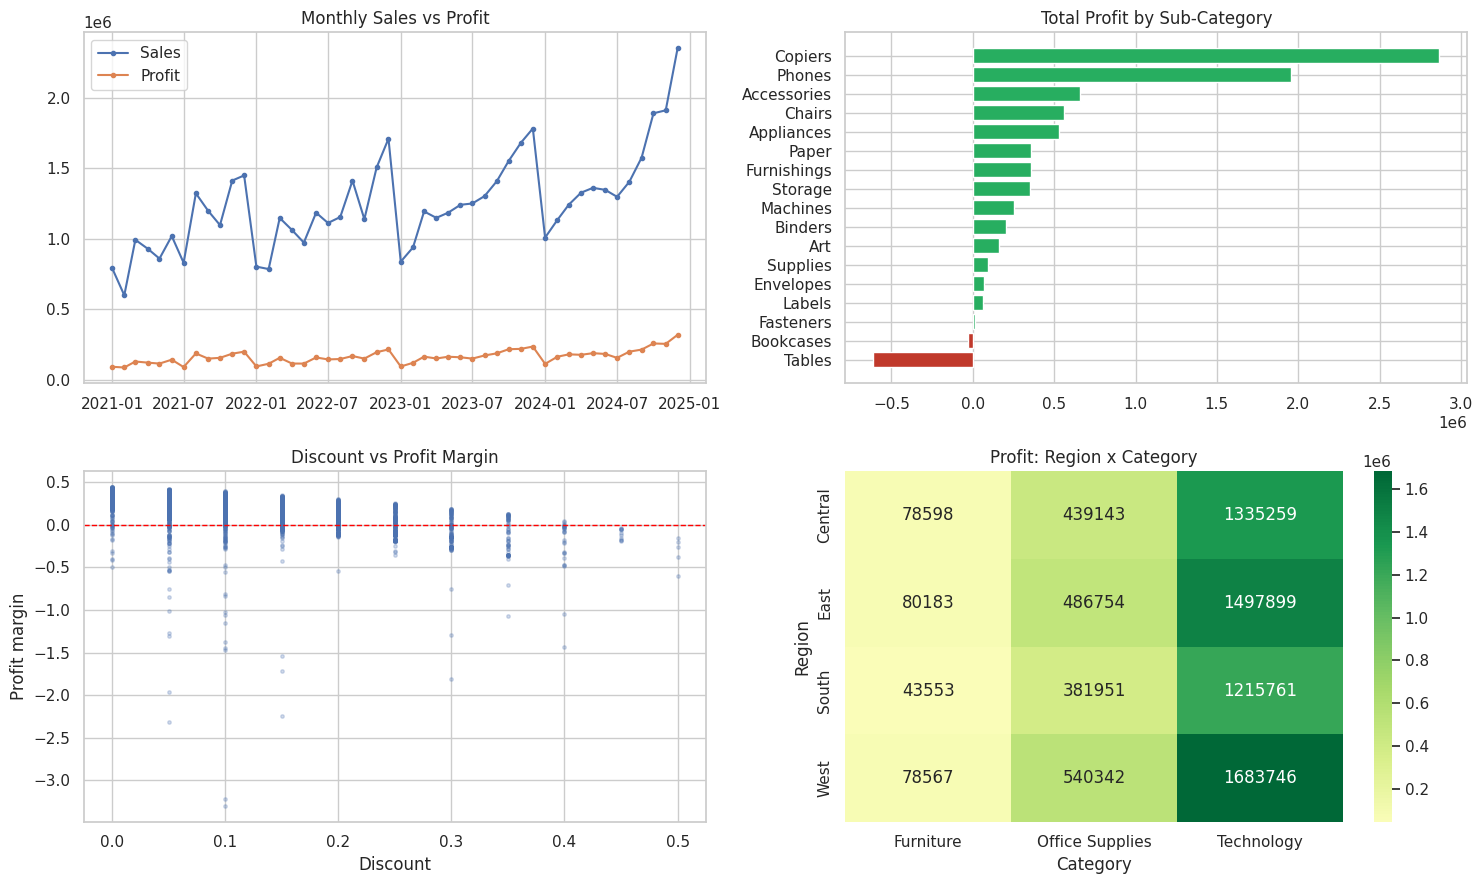

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

m = df.groupby("ym").agg(sales=(S,"sum"), profit=(P,"sum")).reset_index()
ax[0,0].plot(m["ym"], m["sales"], marker="o", ms=3, label="Sales")
ax[0,0].plot(m["ym"], m["profit"], marker="o", ms=3, label="Profit")
ax[0,0].set_title("Monthly Sales vs Profit"); ax[0,0].legend()

sc = df.groupby(COLS["sub_category"])[P].sum().sort_values()
ax[0,1].barh(sc.index, sc.values,
             color=["#c0392b" if v < 0 else "#27ae60" for v in sc.values])
ax[0,1].set_title("Total Profit by Sub-Category")

samp = df.sample(min(4000, len(df)), random_state=42)
ax[1,0].scatter(samp[D], samp["profit_margin"], s=6, alpha=.25)
ax[1,0].axhline(0, color="red", ls="--", lw=1)
ax[1,0].set_xlabel("Discount"); ax[1,0].set_ylabel("Profit margin")
ax[1,0].set_title("Discount vs Profit Margin")

pv = df.pivot_table(index=COLS["region"], columns=COLS["category"], values=P, aggfunc="sum")
sns.heatmap(pv, annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=ax[1,1])
ax[1,1].set_title("Profit: Region x Category")

plt.tight_layout(); plt.savefig("fig1_overview.png", dpi=150, bbox_inches="tight"); plt.show()

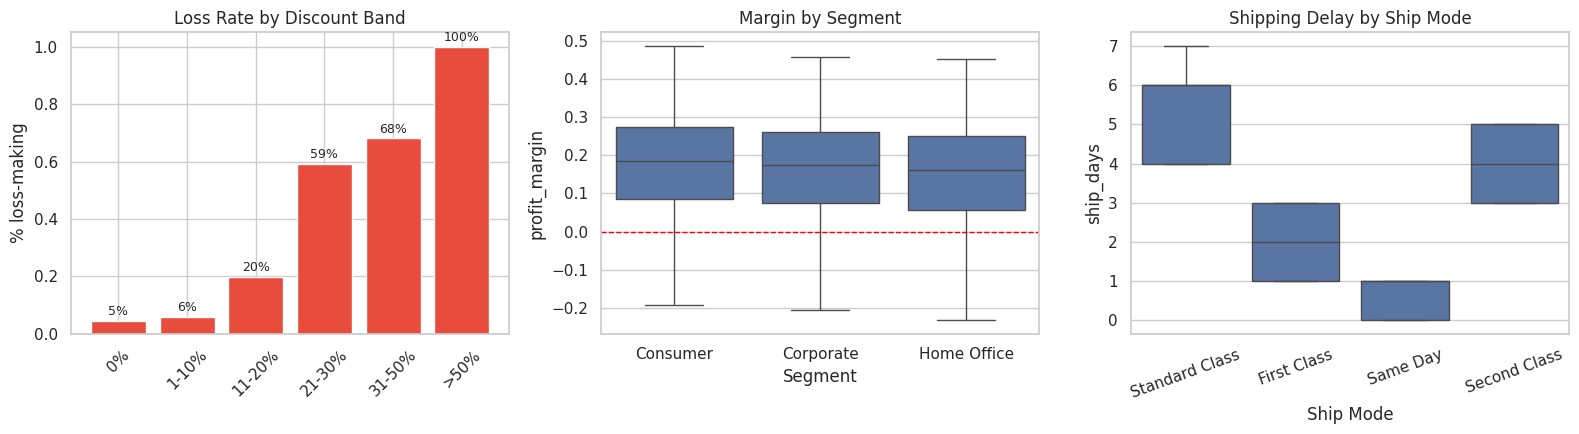

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

lr = df.groupby("discount_band", observed=True)["is_loss"].mean()
ax[0].bar(lr.index.astype(str), lr.values, color="#e74c3c")
ax[0].set_title("Loss Rate by Discount Band"); ax[0].set_ylabel("% loss-making")
ax[0].tick_params(axis="x", rotation=45)
for i, v in enumerate(lr.values):
    ax[0].text(i, v+.02, f"{v:.0%}", ha="center", fontsize=9)

sns.boxplot(data=df, x=COLS["segment"], y="profit_margin", ax=ax[1], showfliers=False)
ax[1].axhline(0, color="red", ls="--", lw=1); ax[1].set_title("Margin by Segment")

sns.boxplot(data=df, x=COLS["ship_mode"], y="ship_days", ax=ax[2], showfliers=False)
ax[2].set_title("Shipping Delay by Ship Mode"); ax[2].tick_params(axis="x", rotation=20)

plt.tight_layout(); plt.savefig("fig2_loss.png", dpi=150, bbox_inches="tight"); plt.show()

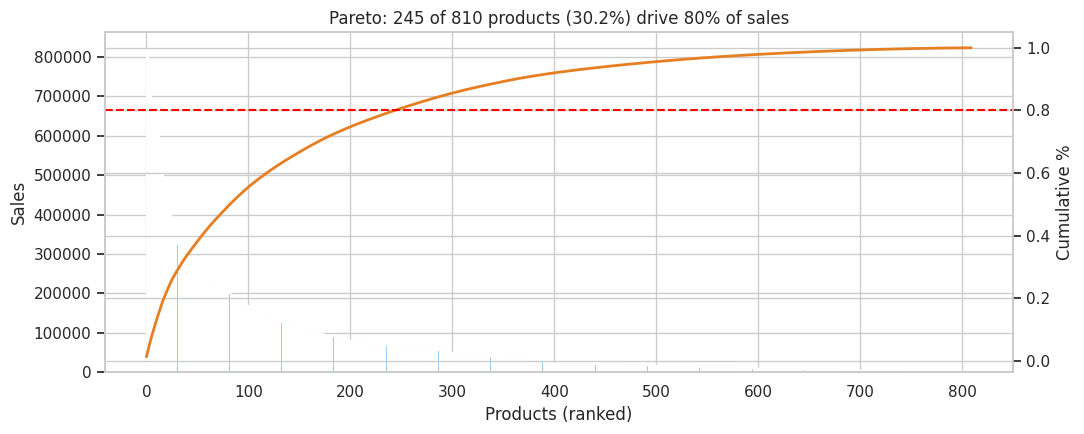

In [ ]:
prod = df.groupby(COLS["product"])[S].sum().sort_values(ascending=False)
cum  = prod.cumsum() / prod.sum()
n80  = int((cum <= 0.80).sum()) + 1

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(range(len(prod)), prod.values, color="#3498db", width=1.0)
ax1.set_ylabel("Sales"); ax1.set_xlabel("Products (ranked)")
ax2 = ax1.twinx(); ax2.plot(range(len(cum)), cum.values, color="#e67e22", lw=2)
ax2.axhline(0.8, color="red", ls="--"); ax2.set_ylabel("Cumulative %")
plt.title(f"Pareto: {n80} of {len(prod)} products ({n80/len(prod):.1%}) drive 80% of sales")
plt.tight_layout(); plt.savefig("fig3_pareto.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
print("="*62)
print("KEY FINDINGS")
print("="*62)

tot_s, tot_p = df[S].sum(), df[P].sum()
print(f"\n1. SCALE")
print(f"   Revenue {tot_s:,.0f} | Profit {tot_p:,.0f} | Margin {tot_p/tot_s:.2%}")
print(f"   {df[COLS['order_id']].nunique():,} orders, "
      f"{df[COLS['customer_id']].nunique():,} customers, "
      f"{df[COLS['product_id']].nunique():,} products")

print(f"\n2. WHERE PROFIT IS DESTROYED")
sc = df.groupby(COLS["sub_category"]).agg(sales=(S,"sum"), profit=(P,"sum"),
                                          disc=(D,"mean"))
sc["margin%"] = 100*sc.profit/sc.sales
for name, r in sc[sc.profit < 0].sort_values("profit").iterrows():
    print(f"   {name:<12} profit {r.profit:>12,.0f}  margin {r['margin%']:>6.1f}%  "
          f"avg discount {r.disc:.0%}")
print(f"   -> these erase {abs(sc[sc.profit<0].profit.sum()):,.0f} "
      f"({abs(sc[sc.profit<0].profit.sum())/tot_p:.0%} of total profit)")

print(f"\n3. THE DISCOUNT CLIFF")
for band, r in df.groupby("discount_band", observed=True).agg(
        n=(P,"size"), loss=("is_loss","mean"), margin=("profit_margin","mean")).iterrows():
    print(f"   {str(band):<7} n={r.n:>7,.0f}  loss rate {r.loss:>5.1%}  "
          f"avg margin {r.margin:>6.1%}")

print(f"\n4. GEOGRAPHY")
rg = df.groupby(COLS["region"]).agg(sales=(S,"sum"), profit=(P,"sum"))
rg["margin%"] = 100*rg.profit/rg.sales
print(rg.sort_values("margin%").round(1).to_string())

print(f"\n5. SEGMENT")
sg = df.groupby(COLS["segment"]).agg(sales=(S,"sum"), profit=(P,"sum"), disc=(D,"mean"))
sg["margin%"] = 100*sg.profit/sg.sales
print(sg.round(3).to_string())

print(f"\n6. GROWTH")
yr = df.groupby("year").agg(sales=(S,"sum"), profit=(P,"sum"),
                            orders=(COLS["order_id"],"nunique"))
yr["sales_yoy%"] = yr.sales.pct_change()*100
yr["margin%"] = 100*yr.profit/yr.sales
print(yr.round(1).to_string())

print(f"\n7. SEASONALITY")
mo = df.groupby("month")[S].sum()
print(f"   Peak month {mo.idxmax()} ({mo.max():,.0f}) | "
      f"Trough month {mo.idxmin()} ({mo.min():,.0f}) | "
      f"ratio {mo.max()/mo.min():.2f}x")

print(f"\n8. CONCENTRATION")
print(f"   {n80} of {len(prod)} products ({n80/len(prod):.1%}) = 80% of revenue")
top10 = df.groupby(COLS["customer_id"])[S].sum().nlargest(int(df[COLS['customer_id']].nunique()*0.1)).sum()
print(f"   Top 10% of customers = {top10/tot_s:.1%} of revenue")

print(f"\n9. OPERATIONS")
print(df.groupby(COLS["ship_mode"]).agg(
    orders=(COLS["order_id"],"nunique"), avg_days=("ship_days","mean")).round(2).to_string())
print("\n" + "="*62)

KEY FINDINGS

1. SCALE
   Revenue 59,837,040 | Profit 7,861,756 | Margin 13.14%
   49,753 orders, 7,708 customers, 810 products

2. WHERE PROFIT IS DESTROYED
   Tables       profit     -610,378  margin  -11.4%  avg discount 20%
   Bookcases    profit      -28,034  margin   -0.9%  avg discount 17%
   -> these erase 638,412 (8% of total profit)

3. THE DISCOUNT CLIFF
   0%      n=  9,544  loss rate  4.6%  avg margin  26.4%
   1-10%   n= 54,104  loss rate  5.9%  avg margin  19.4%
   11-20%  n= 27,619  loss rate 19.7%  avg margin   9.2%
   21-30%  n=  7,992  loss rate 59.2%  avg margin  -3.9%
   31-50%  n=  2,684  loss rate 68.1%  avg margin -16.4%
   >50%    n=     91  loss rate 100.0%  avg margin -54.3%

4. GEOGRAPHY
              sales     profit  margin%
Region                                 
South    12869810.3  1641264.6     12.8
Central  14146998.9  1853000.1     13.1
East     15566851.8  2064835.5     13.3
West     17253379.5  2302655.6     13.3

5. SEGMENT
                   sale

STATISTICAL TESTS

A) Margin ~ Category  (Kruskal-Wallis)
   H = 10,278.6   p = 0.00e+00   epsilon^2 = 0.1007
   effect: moderate
                   mean  median     std
Category                               
Furniture        0.0669  0.0884  0.1589
Office Supplies  0.1669  0.1947  0.2724
Technology       0.1748  0.2073  0.1231

B) Discount band vs loss  (Chi-square)
   chi2 = 22,990.3   dof = 5   p = 0.00e+00   Cramer's V = 0.475
   effect: strong
is_loss            0     1
discount_band             
0%              9102   442
1-10%          50926  3178
11-20%         22166  5453
21-30%          3262  4730
31-50%           856  1828
>50%               0    91

C) Is mean profit < 0 for the flagged sub-categories?
   Tables     mean   -117.16  t =   -34.72  p = 8.49e-238  n = 5,210
   Bookcases  mean     -6.33  t =    -5.24  p = 1.72e-07  n = 4,432

D) Spearman correlations with Profit:
Discount        -0.295
ship_days        0.073
Quantity         0.385
unit_price       0.437
profit_m

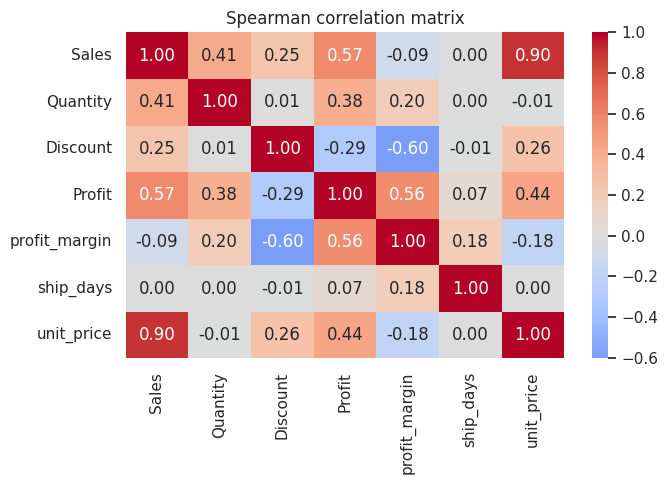


E) Profit outliers (IQR): 15,057 rows (14.8%)
   bounds [-91.16, 166.44]
   they hold 65.3% of total profit



In [ ]:
from scipy import stats

print("="*62); print("STATISTICAL TESTS"); print("="*62)
n = len(df)

# --- A) Does margin differ across categories? (non-normal -> Kruskal-Wallis)
groups = [g["profit_margin"].values for _, g in df.groupby(COLS["category"])]
k = len(groups)
h, p_kw = stats.kruskal(*groups)
eps2 = (h - k + 1) / (n - k)                       # epsilon-squared effect size
print(f"\nA) Margin ~ Category  (Kruskal-Wallis)")
print(f"   H = {h:,.1f}   p = {p_kw:.2e}   epsilon^2 = {eps2:.4f}")
print(f"   effect: {'negligible' if eps2<.01 else 'small' if eps2<.06 else 'moderate' if eps2<.14 else 'large'}")
print(df.groupby(COLS["category"])["profit_margin"].agg(["mean","median","std"]).round(4).to_string())

# --- B) Is discount band associated with loss? (Chi-square + Cramer's V)
ct = pd.crosstab(df["discount_band"], df["is_loss"])
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
cramv = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"\nB) Discount band vs loss  (Chi-square)")
print(f"   chi2 = {chi2:,.1f}   dof = {dof}   p = {p_chi:.2e}   Cramer's V = {cramv:.3f}")
print(f"   effect: {'weak' if cramv<.2 else 'moderate' if cramv<.4 else 'strong'}")
print(ct.to_string())

# --- C) Do the two flagged sub-categories really lose money? (one-sample t-test)
print(f"\nC) Is mean profit < 0 for the flagged sub-categories?")
for sub in ["Tables", "Bookcases"]:
    v = df.loc[df[COLS["sub_category"]] == sub, P]
    t, pv = stats.ttest_1samp(v, 0)
    print(f"   {sub:<10} mean {v.mean():>9.2f}  t = {t:>8.2f}  p = {pv:.2e}  n = {len(v):,}")

# --- D) Correlations (Spearman - relationships are monotonic, not linear)
num = df[[S, Q, D, P, "profit_margin", "ship_days", "unit_price"]]
corr = num.corr(method="spearman")
print(f"\nD) Spearman correlations with Profit:")
print(corr[P].drop(P).sort_values().round(3).to_string())

plt.figure(figsize=(7,5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation matrix"); plt.tight_layout()
plt.savefig("fig4_corr.png", dpi=150, bbox_inches="tight"); plt.show()

# --- E) Outliers
q1, q3 = df[P].quantile([.25,.75]); iqr = q3-q1
lo, hi = q1-1.5*iqr, q3+1.5*iqr
out = df[(df[P]<lo)|(df[P]>hi)]
print(f"\nE) Profit outliers (IQR): {len(out):,} rows ({len(out)/n:.1%})")
print(f"   bounds [{lo:.2f}, {hi:.2f}]")
print(f"   they hold {out[P].sum()/df[P].sum():.1%} of total profit")
print("\n" + "="*62)

RFM built for 7,708 customers

             customers  avg_recency  avg_freq  avg_spend  total_revenue  total_profit  rev_share%  margin%
segment_rfm                                                                                               
Champions         2123         63.6      14.9    19168.3     40694212.7     5427963.6        68.0     13.3
Loyal             1710        155.9       4.8     5869.2     10036408.0     1280238.0        16.8     12.8
Potential         1770        271.0       3.3     3503.1      6200481.4      774945.5        10.4     12.5
At Risk           1432        464.8       2.2     1761.9      2523034.9      325229.1         4.2     12.9
Lost               673        822.1       1.4      569.0       382903.5       53379.6         0.6     13.9

Unprofitable customers: 634 of 7,708 (8.2%), destroying -165,192


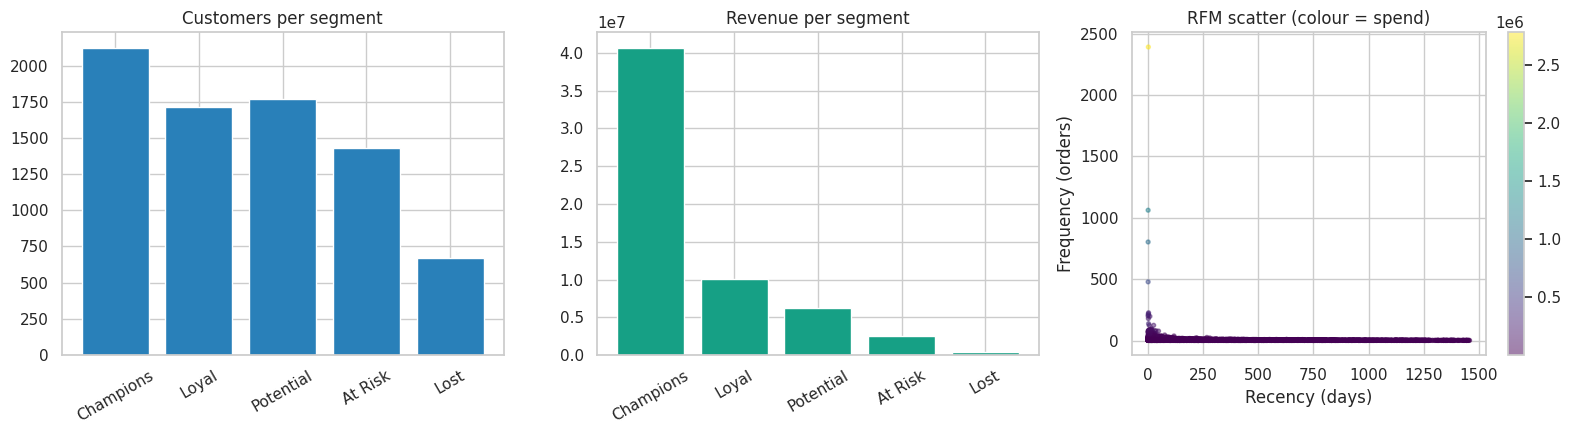


>>> rfm is ready. Now re-run Cell 11.


In [ ]:
snapshot = df[COLS["order_date"]].max() + pd.Timedelta(days=1)
CID = COLS["customer_id"]

rfm = df.groupby(CID).agg(
    recency   = (COLS["order_date"], lambda x: (snapshot - x.max()).days),
    frequency = (COLS["order_id"], "nunique"),
    monetary  = (S, "sum"),
    profit    = (P, "sum"),
).reset_index()
print(f"RFM built for {len(rfm):,} customers")

# rank first -> no tied values -> qcut can never fail on duplicate edges
rfm["R"] = pd.qcut(rfm["recency"].rank(method="first"),   4, labels=[4,3,2,1]).astype(int)
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 4, labels=[1,2,3,4]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"),  4, labels=[1,2,3,4]).astype(int)
rfm["rfm_score"] = rfm[["R","F","M"]].sum(axis=1)

rfm["segment_rfm"] = rfm["rfm_score"].apply(
    lambda s: "Champions" if s>=10 else "Loyal" if s>=8
              else "Potential" if s>=6 else "At Risk" if s>=4 else "Lost")

summary = rfm.groupby("segment_rfm").agg(
    customers=(CID,"count"), avg_recency=("recency","mean"),
    avg_freq=("frequency","mean"), avg_spend=("monetary","mean"),
    total_revenue=("monetary","sum"), total_profit=("profit","sum"),
).round(1)
summary["rev_share%"] = (100*summary.total_revenue/summary.total_revenue.sum()).round(1)
summary["margin%"]    = (100*summary.total_profit/summary.total_revenue).round(1)
print("\n" + summary.sort_values("total_revenue", ascending=False).to_string())

print(f"\nUnprofitable customers: {(rfm.profit<0).sum():,} of {len(rfm):,} "
      f"({(rfm.profit<0).mean():.1%}), destroying {rfm.loc[rfm.profit<0,'profit'].sum():,.0f}")

fig, ax = plt.subplots(1, 3, figsize=(16,4.5))
order = [o for o in ["Champions","Loyal","Potential","At Risk","Lost"] if o in summary.index]
s2 = summary.reindex(order)
ax[0].bar(s2.index, s2.customers, color="#2980b9"); ax[0].set_title("Customers per segment")
ax[1].bar(s2.index, s2.total_revenue, color="#16a085"); ax[1].set_title("Revenue per segment")
sc_ = ax[2].scatter(rfm.recency, rfm.frequency, c=rfm.monetary, s=8, cmap="viridis", alpha=.5)
ax[2].set_xlabel("Recency (days)"); ax[2].set_ylabel("Frequency (orders)")
ax[2].set_title("RFM scatter (colour = spend)"); plt.colorbar(sc_, ax=ax[2])
for a in ax[:2]: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("fig5_rfm.png", dpi=150, bbox_inches="tight"); plt.show()

assert "rfm" in dir(), "rfm missing"
print("\n>>> rfm is ready. Now re-run Cell 11.")

In [ ]:
import time
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, RocCurveDisplay,
                             precision_recall_curve, average_precision_score)
from sklearn.inspection import permutation_importance

num_feats = [D, Q, S, "unit_price", "ship_days"]
cat_feats = [COLS["category"], COLS["sub_category"], COLS["region"],
             COLS["segment"], COLS["ship_mode"]]

X, y = df[num_feats + cat_feats], df["is_loss"]
print(f"Training on {len(X):,} rows | positive class {y.mean():.1%}")

try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
pre = ColumnTransformer([("num", StandardScaler(), num_feats),
                         ("cat", ohe, cat_feats)])

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.25,
                                          random_state=42, stratify=y)

models = {
 "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
 "RandomForest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                       class_weight="balanced", random_state=42, n_jobs=-1),
 "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
}

results, fitted = {}, {}
cv = StratifiedKFold(3, shuffle=True, random_state=42)
for name, m in models.items():
    t0 = time.time()
    pipe = Pipeline([("pre", pre), ("clf", m)])
    s = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="roc_auc", n_jobs=-1)
    pipe.fit(X_tr, y_tr)
    proba = pipe.predict_proba(X_te)[:,1]
    auc, ap = roc_auc_score(y_te, proba), average_precision_score(y_te, proba)
    results[name] = {"cv_auc": s.mean(), "test_auc": auc, "avg_prec": ap}
    fitted[name] = pipe
    print(f"{name:22s} CV AUC {s.mean():.4f}  Test AUC {auc:.4f}  "
          f"AvgPrec {ap:.4f}  ({time.time()-t0:.0f}s)")

best_name = max(results, key=lambda k: results[k]["test_auc"])
best = fitted[best_name]
print(f"\nBEST: {best_name}\n")
print(classification_report(y_te, best.predict(X_te),
                            target_names=["Profitable","Loss"], digits=3))

Training on 102,034 rows | positive class 15.4%
LogisticRegression     CV AUC 0.9479  Test AUC 0.9493  AvgPrec 0.8348  (11s)
RandomForest           CV AUC 0.9993  Test AUC 0.9995  AvgPrec 0.9975  (65s)
HistGradientBoosting   CV AUC 0.9998  Test AUC 0.9999  AvgPrec 0.9994  (11s)

BEST: HistGradientBoosting

              precision    recall  f1-score   support

  Profitable      0.997     0.999     0.998     21578
        Loss      0.993     0.982     0.988      3931

    accuracy                          0.996     25509
   macro avg      0.995     0.990     0.993     25509
weighted avg      0.996     0.996     0.996     25509



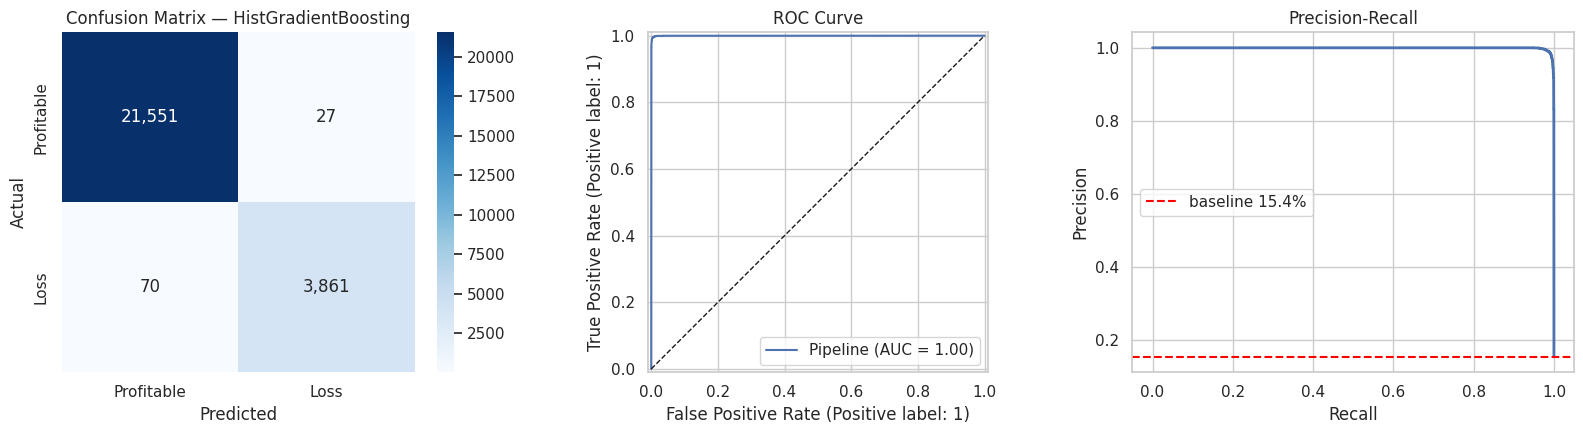

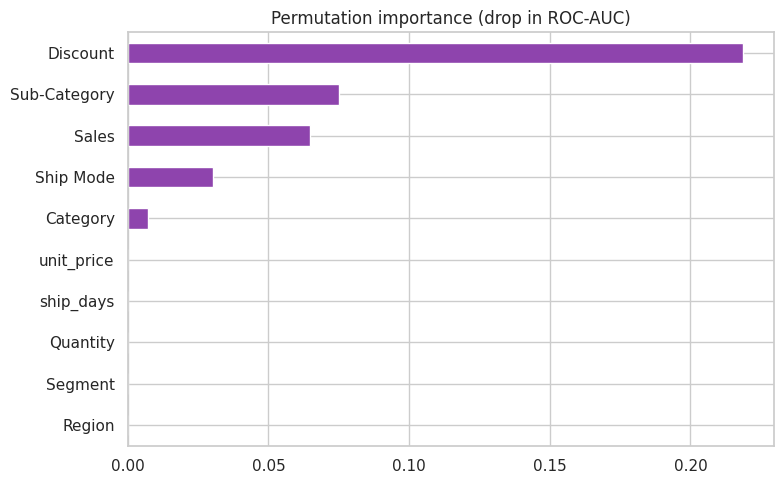

Discount        0.2188
Sub-Category    0.0752
Sales           0.0646
Ship Mode       0.0302
Category        0.0071
unit_price      0.0002
ship_days       0.0001
Quantity        0.0000
Segment         0.0000
Region         -0.0000


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

cm = confusion_matrix(y_te, best.predict(X_te))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=ax[0],
            xticklabels=["Profitable","Loss"], yticklabels=["Profitable","Loss"])
ax[0].set_title(f"Confusion Matrix — {best_name}")
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")

RocCurveDisplay.from_estimator(best, X_te, y_te, ax=ax[1])
ax[1].plot([0,1],[0,1],"k--",lw=1); ax[1].set_title("ROC Curve")

prec, rec, _ = precision_recall_curve(y_te, best.predict_proba(X_te)[:,1])
ax[2].plot(rec, prec, lw=2); ax[2].axhline(y_te.mean(), color="red", ls="--",
                                           label=f"baseline {y_te.mean():.1%}")
ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision")
ax[2].set_title("Precision-Recall"); ax[2].legend()
plt.tight_layout(); plt.savefig("fig6_model.png", dpi=150, bbox_inches="tight"); plt.show()

# permutation importance on a 20k subsample (full test set would be slow)
sub = X_te.sample(min(20000, len(X_te)), random_state=42)
perm = permutation_importance(best, sub, y_te.loc[sub.index], n_repeats=4,
                              random_state=42, scoring="roc_auc", n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()
plt.figure(figsize=(8,5)); imp.plot(kind="barh", color="#8e44ad")
plt.title("Permutation importance (drop in ROC-AUC)"); plt.tight_layout()
plt.savefig("fig7_importance.png", dpi=150, bbox_inches="tight"); plt.show()
print(imp.sort_values(ascending=False).round(4).to_string())

48 monthly periods: 2021-01-01 -> 2024-12-01


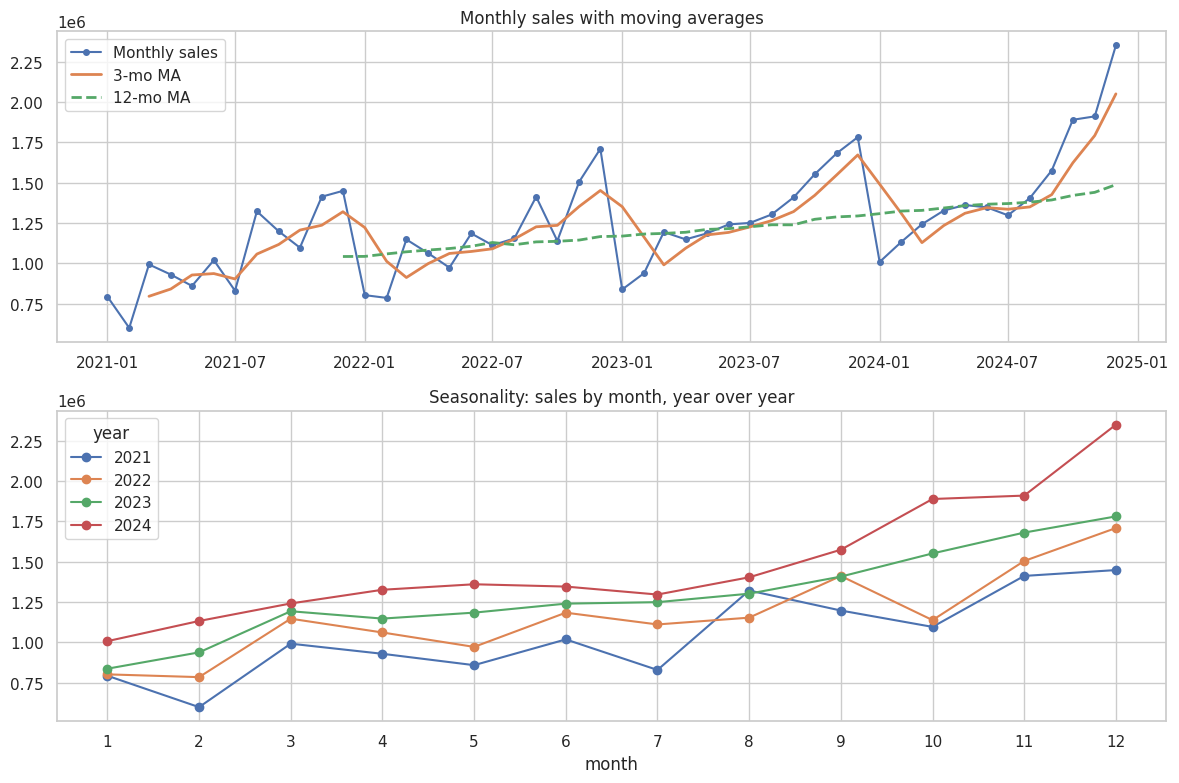

In [ ]:
ts = df.set_index(COLS["order_date"])[S].resample("MS").sum()
print(f"{len(ts)} monthly periods: {ts.index.min().date()} -> {ts.index.max().date()}")

fig, ax = plt.subplots(2, 1, figsize=(12, 8))
ax[0].plot(ts.index, ts.values, marker="o", ms=4, label="Monthly sales")
ax[0].plot(ts.index, ts.rolling(3).mean(), lw=2, label="3-mo MA")
ax[0].plot(ts.index, ts.rolling(12).mean(), lw=2, ls="--", label="12-mo MA")
ax[0].set_title("Monthly sales with moving averages"); ax[0].legend()

piv = df.pivot_table(index="month", columns="year", values=S, aggfunc="sum")
piv.plot(ax=ax[1], marker="o")
ax[1].set_title("Seasonality: sales by month, year over year"); ax[1].set_xticks(range(1,13))
plt.tight_layout(); plt.savefig("fig8_timeseries.png", dpi=150, bbox_inches="tight"); plt.show()

HOLDOUT VALIDATION (last 6 months)
  MAPE 11.11%   RMSE 285,441
               actual   forecast  error%
2024-07-01  1296972.0  1273037.0    -1.8
2024-08-01  1403786.0  1541237.0     9.8
2024-09-01  1574695.0  1606281.0     2.0
2024-10-01  1889203.0  1419308.0   -24.9
2024-11-01  1910285.0  1758255.0    -8.0
2024-12-01  2349967.0  1876173.0   -20.2


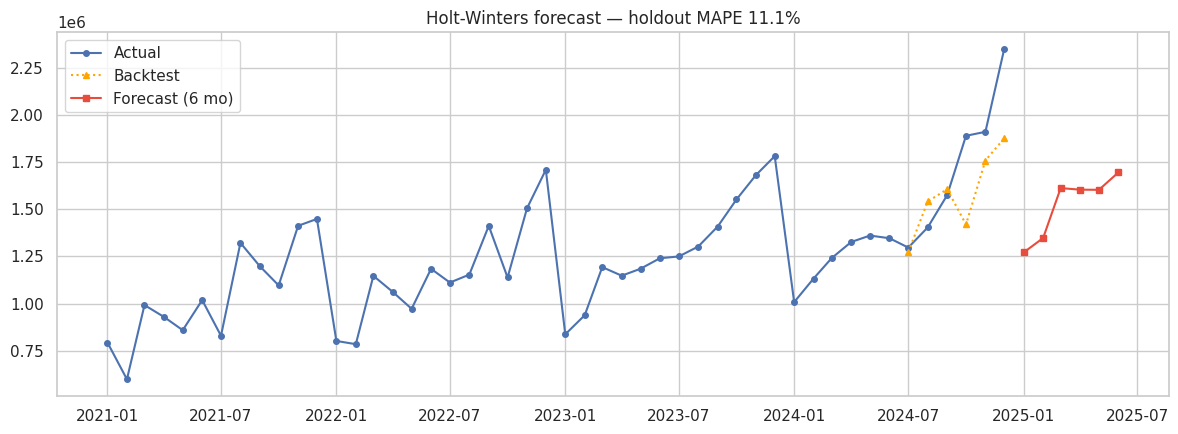

2025-01-01    1271033.0
2025-02-01    1347441.0
2025-03-01    1612077.0
2025-04-01    1603752.0
2025-05-01    1602988.0
2025-06-01    1695076.0
Freq: MS


In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

H = 6
train, test = ts[:-H], ts[-H:]

fit = ExponentialSmoothing(train, trend="add", seasonal="add",
                           seasonal_periods=12).fit()
pred = fit.forecast(H)

mape = (np.abs(test.values - pred.values) / test.values).mean() * 100
rmse = np.sqrt(((test.values - pred.values)**2).mean())
print(f"HOLDOUT VALIDATION (last {H} months)")
print(f"  MAPE {mape:.2f}%   RMSE {rmse:,.0f}")
print(pd.DataFrame({"actual": test.round(0), "forecast": pred.round(0),
                    "error%": ((pred-test)/test*100).round(1)}).to_string())

# refit on all data, forecast forward
final = ExponentialSmoothing(ts, trend="add", seasonal="add",
                             seasonal_periods=12).fit()
fc = final.forecast(H)

plt.figure(figsize=(12,4.5))
plt.plot(ts.index, ts.values, label="Actual", marker="o", ms=4)
plt.plot(pred.index, pred.values, label="Backtest", marker="^", ms=5, ls=":", color="orange")
plt.plot(fc.index, fc.values, label=f"Forecast ({H} mo)", marker="s", ms=5, color="#e74c3c")
plt.title(f"Holt-Winters forecast — holdout MAPE {mape:.1f}%"); plt.legend()
plt.tight_layout(); plt.savefig("fig9_forecast.png", dpi=150, bbox_inches="tight"); plt.show()
print(fc.round(0).to_string())

RFM built for 7,708 customers

             customers  avg_recency  avg_freq  avg_spend  total_revenue  total_profit  rev_share%  margin%
segment_rfm                                                                                               
Champions         2123         63.6      14.9    19168.3     40694212.7     5427963.6        68.0     13.3
Loyal             1710        155.9       4.8     5869.2     10036408.0     1280238.0        16.8     12.8
Potential         1770        271.0       3.3     3503.1      6200481.4      774945.5        10.4     12.5
At Risk           1432        464.8       2.2     1761.9      2523034.9      325229.1         4.2     12.9
Lost               673        822.1       1.4      569.0       382903.5       53379.6         0.6     13.9

Unprofitable customers: 634 of 7,708 (8.2%), destroying -165,192


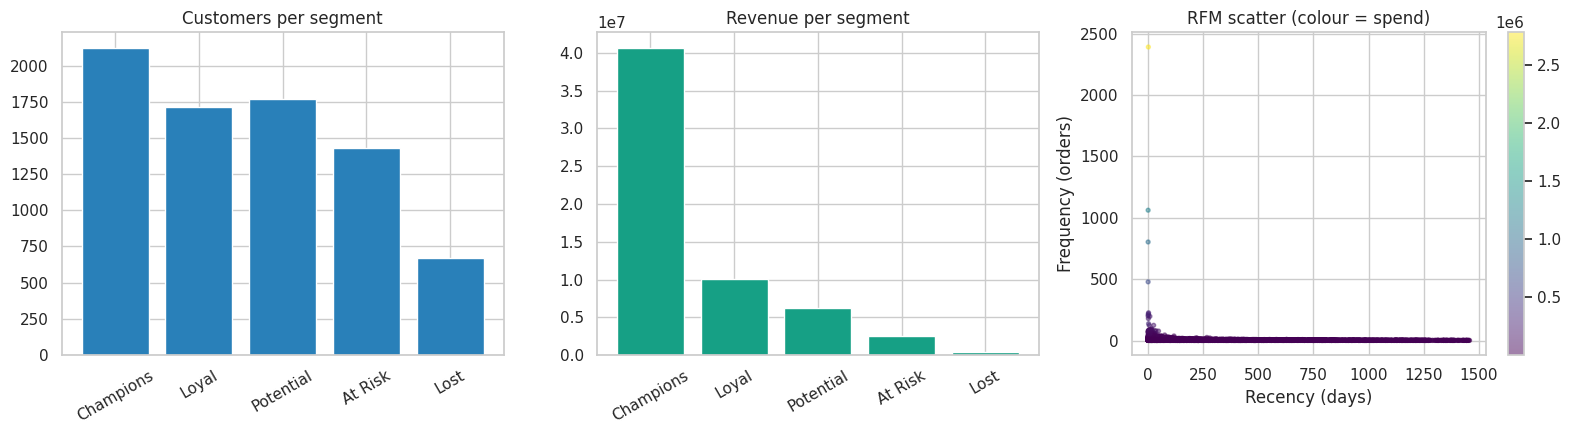


>>> rfm is ready. Now re-run Cell 11.


In [ ]:
snapshot = df[COLS["order_date"]].max() + pd.Timedelta(days=1)
CID = COLS["customer_id"]

rfm = df.groupby(CID).agg(
    recency   = (COLS["order_date"], lambda x: (snapshot - x.max()).days),
    frequency = (COLS["order_id"], "nunique"),
    monetary  = (S, "sum"),
    profit    = (P, "sum"),
).reset_index()
print(f"RFM built for {len(rfm):,} customers")

# rank before binning -> no tied values -> qcut cannot fail
rfm["R"] = pd.qcut(rfm["recency"].rank(method="first"),   4, labels=[4,3,2,1]).astype(int)
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 4, labels=[1,2,3,4]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"),  4, labels=[1,2,3,4]).astype(int)
rfm["rfm_score"] = rfm[["R","F","M"]].sum(axis=1)

rfm["segment_rfm"] = rfm["rfm_score"].apply(
    lambda s: "Champions" if s >= 10 else "Loyal" if s >= 8
              else "Potential" if s >= 6 else "At Risk" if s >= 4 else "Lost")

summary = rfm.groupby("segment_rfm").agg(
    customers     = (CID, "count"),
    avg_recency   = ("recency", "mean"),
    avg_freq      = ("frequency", "mean"),
    avg_spend     = ("monetary", "mean"),
    total_revenue = ("monetary", "sum"),
    total_profit  = ("profit", "sum"),
).round(1)
summary["rev_share%"] = (100 * summary.total_revenue / summary.total_revenue.sum()).round(1)
summary["margin%"]    = (100 * summary.total_profit / summary.total_revenue).round(1)
print("\n" + summary.sort_values("total_revenue", ascending=False).to_string())

print(f"\nUnprofitable customers: {(rfm.profit < 0).sum():,} of {len(rfm):,} "
      f"({(rfm.profit < 0).mean():.1%}), "
      f"destroying {rfm.loc[rfm.profit < 0, 'profit'].sum():,.0f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
order = [o for o in ["Champions","Loyal","Potential","At Risk","Lost"] if o in summary.index]
s2 = summary.reindex(order)
ax[0].bar(s2.index, s2.customers, color="#2980b9")
ax[0].set_title("Customers per segment")
ax[1].bar(s2.index, s2.total_revenue, color="#16a085")
ax[1].set_title("Revenue per segment")
sc_ = ax[2].scatter(rfm.recency, rfm.frequency, c=rfm.monetary, s=8, cmap="viridis", alpha=.5)
ax[2].set_xlabel("Recency (days)"); ax[2].set_ylabel("Frequency (orders)")
ax[2].set_title("RFM scatter (colour = spend)")
plt.colorbar(sc_, ax=ax[2])
for a in ax[:2]:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("fig5_rfm.png", dpi=150, bbox_inches="tight"); plt.show()

print("\n>>> rfm is ready. Now re-run Cell 11.")

In [ ]:
# ===== ONE CELL: Kaggle -> clean -> features -> RFM -> model -> export =====
!pip -q install kagglehub

import pandas as pd, numpy as np, os, shutil, warnings
warnings.filterwarnings("ignore")
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

SLUG = "abhishiktadutta/syn-retail-sales-and-profitable-dataset-2021-24"

# ---- 1. load
p = kagglehub.dataset_download(SLUG)
CSV = [os.path.join(r,f) for r,_,fs in os.walk(p) for f in fs if f.endswith(".csv")][0]
df = pd.read_csv(CSV)
print("loaded", df.shape)

# ---- 2. clean
df.columns = [c.strip() for c in df.columns]
df = df.drop(columns=["Row ID"], errors="ignore").drop_duplicates()
for c in df.select_dtypes("object").columns:
    df[c] = df[c].astype(str).str.strip()
df["Ship Mode"] = df["Ship Mode"].str.title()
df["Region"] = df["Region"].replace({"Wets":"West","Est":"East","Centrl":"Central","Sout":"South"})
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True, errors="coerce")
df["Ship Date"]  = pd.to_datetime(df["Ship Date"],  dayfirst=True, errors="coerce")
df["Postal Code"] = df["Postal Code"].fillna(-1).astype(int)
df = df.dropna(subset=["Order Date","Ship Date"])
df["ship_days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df = df[(df.ship_days >= 0) & (df.Quantity > 0) & (df.Sales > 0)]
print("clean", df.shape)

# ---- 3. features
df["cost"] = df.Sales - df.Profit
df["unit_price"] = df.Sales / df.Quantity
df["profit_margin"] = df.Profit / df.Sales
df["is_loss"] = (df.Profit < 0).astype(int)
df["discount_band"] = pd.cut(df.Discount, [-.001,0,.1,.2,.3,.5,1],
    labels=["0%","1-10%","11-20%","21-30%","31-50%",">50%"])
od = df["Order Date"]
df["year"], df["month"] = od.dt.year, od.dt.month
df["quarter"] = "Q" + od.dt.quarter.astype(str)
df["ym"] = od.dt.to_period("M").dt.to_timestamp()
df["day_name"] = od.dt.day_name()
print(f"margin {df.Profit.sum()/df.Sales.sum():.2%} | loss {df.is_loss.mean():.1%}")

# ---- 4. RFM
snap = df["Order Date"].max() + pd.Timedelta(days=1)
rfm = df.groupby("Customer ID").agg(
    recency=("Order Date", lambda x:(snap-x.max()).days),
    frequency=("Order ID","nunique"), monetary=("Sales","sum"), profit=("Profit","sum"),
).reset_index()
rfm["R"] = pd.qcut(rfm.recency.rank(method="first"),   4, labels=[4,3,2,1]).astype(int)
rfm["F"] = pd.qcut(rfm.frequency.rank(method="first"), 4, labels=[1,2,3,4]).astype(int)
rfm["M"] = pd.qcut(rfm.monetary.rank(method="first"),  4, labels=[1,2,3,4]).astype(int)
rfm["rfm_score"] = rfm[["R","F","M"]].sum(axis=1)
rfm["segment_rfm"] = rfm.rfm_score.apply(lambda s: "Champions" if s>=10 else "Loyal"
    if s>=8 else "Potential" if s>=6 else "At Risk" if s>=4 else "Lost")
print("rfm", rfm.shape)

# ---- 5. model
NUM = ["Discount","Quantity","Sales","unit_price","ship_days"]
CAT = ["Category","Sub-Category","Region","Segment","Ship Mode"]
try: ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError: ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
pipe = Pipeline([("pre", ColumnTransformer([("n",StandardScaler(),NUM),("c",ohe,CAT)])),
                 ("m", HistGradientBoostingClassifier(random_state=42))])
Xtr,Xte,ytr,yte = train_test_split(df[NUM+CAT], df.is_loss, test_size=.25,
                                   random_state=42, stratify=df.is_loss)
pipe.fit(Xtr,ytr)
AUC = roc_auc_score(yte, pipe.predict_proba(Xte)[:,1])
print(f"model AUC {AUC:.4f}")
df["loss_risk"] = pipe.predict_proba(df[NUM+CAT])[:,1].round(4)

# ---- 6. export
os.makedirs("powerbi", exist_ok=True)
dim_customer = (df[["Customer ID","Customer Name","Segment"]].drop_duplicates("Customer ID")
                .merge(rfm[["Customer ID","recency","frequency","monetary",
                            "rfm_score","segment_rfm"]], on="Customer ID", how="left"))
dim_product = df[["Product ID","Product Name","Category","Sub-Category"]].drop_duplicates("Product ID")
dim_geo = df[["Country","Region","State","City"]].drop_duplicates().reset_index(drop=True)
dim_geo.insert(0,"geo_key", dim_geo.index+1)
fact = df.merge(dim_geo, on=["Country","Region","State","City"], how="left")
fact_orders = fact[["Order ID","Order Date","Ship Date","Ship Mode","Customer ID",
    "Product ID","geo_key","Sales","Quantity","Discount","Profit","cost",
    "profit_margin","is_loss","ship_days","discount_band","loss_risk"]]

for nm,t in [("dim_customer",dim_customer),("dim_product",dim_product),
             ("dim_geo",dim_geo),("fact_orders",fact_orders)]:
    t.to_csv(f"powerbi/{nm}.csv", index=False); print(f"{nm:14s} {len(t):>7,} rows")

print(f"\nCONTROL TOTALS")
print(f"  Total Sales  {fact_orders.Sales.sum():,.2f}")
print(f"  Total Profit {fact_orders.Profit.sum():,.2f}")
print(f"  Total Orders {fact_orders['Order ID'].nunique():,}")
print(f"  Margin       {fact_orders.Profit.sum()/fact_orders.Sales.sum():.4%}")
print(f"  Model AUC    {AUC:.4f}")

shutil.make_archive("powerbi_data","zip","powerbi")
from google.colab import files
files.download("powerbi_data.zip")

Using Colab cache for faster access to the 'syn-retail-sales-and-profitable-dataset-2021-24' dataset.
loaded (104820, 21)
clean (102034, 21)
margin 13.14% | loss 15.4%
rfm (7708, 10)
model AUC 0.9999
dim_customer     7,708 rows
dim_product        810 rows
dim_geo             45 rows
fact_orders    102,034 rows

CONTROL TOTALS
  Total Sales  59,837,040.46
  Total Profit 7,861,755.71
  Total Orders 49,753
  Margin       13.1386%
  Model AUC    0.9999


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>